# When should a factory robot ask a person? The decision ladder, scored once

A simulated **MH3 robot** sorts painted metal parts on a table into a **good tray** (green) and a **rework tray** (orange), in the Genesis physics simulator. Most of the job is motion. Four moments are **judgement calls**, and a wrong call there is what costs a factory money:

| question | what the robot has to decide | options |
|---|---|---|
| `finish` | is the paint on this part good or defective? | good / defective |
| `in_bin` | did the part land inside the tray it was meant for? | yes / no |
| `sort_complete` | is the sort finished: every part in a tray, table clear? | yes / no |
| `safe_to_grasp` | close the hand on the part now? | grasp / re_look / ask_operator / abort |

Each call goes to a vision-language model, **d3 27B** (`d3-27b-vision`, run locally with llama.cpp on one GPU), which sees the camera frame and a short description of the scene and gives a probability for every option.

**The ladder** is one rule: if d3's top probability is **at least 0.80**, the robot acts on d3's answer; **below 0.80, the call goes to a person** on an operator page. That one number trades two costs: acting wrong (a bad part ships) against asking too often (the person becomes the bottleneck).

This notebook recomputes the published results of that ladder from the decision log, with only numpy and matplotlib.

**Phase 2** (at the end): the same design on a soft-gel capsule cell, where a VDM and a VLM built on the same base model answer the same pictures; its ladder was frozen and scored once on test05.


## How the test was run: picked on one log, scored once on another

The threshold was not tuned on the numbers below. The order of events:

1. **test03** (an earlier log, 974 labelled decisions) was used to choose the ladder and fit the threshold. The cost was set from the shop floor: **a wrong action costs 10 times a hand-off** (a bad seat that ships means an angry call from the customer), so a hand-off is worth 0.8 of a right answer and a wrong action is -1.
2. The ladder (d3 27B alone, then the person) and the threshold (**0.80**) were written into a pre-registration file and committed **before** the test log was opened, with a prediction for each rate.
3. **test04** is that test log: **300 new episodes** (seeds 1000 to 1299, never used before), 100 clean, 100 with a forced drop during the carry, 100 crowded (a part too close to another, which cannot be finished by design). While the log was made, a scripted oracle answered every question, so **every decision has a known right answer** (the truth).
4. d3 answered all 3,262 test04 decisions once. They were scored once with the frozen threshold, no refit.

**The headline is the judgement questions** (`finish`, `in_bin`, `sort_complete`): in the running robot, `safe_to_grasp` is decided by a hard rule from the simulator state (part on the floor, a neighbour too close) before any model is asked.

What the rates mean, per decision:

- **acted wrong**: d3 was at or over 0.80 and its answer was not the truth. *The number a factory cares about.*
- **confidently wrong**: acted wrong at 0.9 confidence or more.
- **handed to a person**: d3 was under 0.80. (The person is counted as right.)
- **decided alone and right**: d3 was at or over 0.80 and right.

Intervals are 95% by-episode bootstrap intervals (1,000 resamples of whole episodes, seed 0), because the decisions inside one episode share the same parts, trays and camera.

In [1]:
import csv
import json
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.edgecolor": "#c9c8c2", "axes.grid": True, "grid.color": "#e7e6e1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})
BLUE, AQUA, ORANGE, INK, MUTED = "#2a78d6", "#1baf7a", "#eb6834", "#0b0b0b", "#52514e"


def find(name):
    # Next to this notebook (data/), or attached as a Kaggle dataset under /kaggle/input.
    for p in [Path("data") / name, *sorted(Path("/kaggle/input").glob(f"**/{name}"))]:
        if p.exists():
            return p
    raise FileNotFoundError(name)


with find("test04_decisions.csv").open(encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
frozen = json.loads(find("frozen_ladder.json").read_text(encoding="utf-8"))

question = np.array([r["question"] for r in rows])
episode = np.array([r["episode"] for r in rows])
fault = np.array([r["fault"] for r in rows])
truth = np.array([r["truth"] for r in rows])
d3_answer = np.array([r["d3_answer"] for r in rows])
d3_conf = np.array([float(r["d3_confidence"]) for r in rows])
rule_decided = np.array([r["rule_decided"] == "1" for r in rows])
rule_answer = np.array([r["rule_answer"] for r in rows])
part_was = np.array([r["part_was"] for r in rows])
judgement = question != "safe_to_grasp"

(ARM,) = frozen["rungs"]
THRESHOLD = frozen["thresholds"][ARM]
print(f"{len(rows):,} decisions in {len(set(episode))} episodes; by question: {dict(Counter(r['question'] for r in rows))}")
print(f"by fault type (episodes): {dict(Counter(r['fault'] for r in {r['episode']: r for r in rows}.values()))}")
print(f"frozen ladder: {ARM} > person, threshold {THRESHOLD}, human_cost {frozen['human_cost']}")

3,262 decisions in 300 episodes; by question: {'finish': 900, 'safe_to_grasp': 1000, 'in_bin': 949, 'sort_complete': 413}
by fault type (episodes): {'clean': 100, 'drop_on_carry': 100, 'crowded': 100}
frozen ladder: d3-27b-vision > person, threshold 0.8, human_cost 0.2


## The ladder and the four rates

`ladder()` turns each decision into one outcome: the machine acted (right or wrong, with its confidence) or the person took it. `rates()` gives the four rates with their by-episode bootstrap interval. This is the same arithmetic as the repo's `scripts/freeze_ladder.py confirm`, written out so it runs on the extract alone.

In [2]:
CONFIDENT = 0.9  # "confidently wrong" = acted wrong at this confidence or more


def ladder(threshold=THRESHOLD, live=False):
    # Returns (wrong, person, confidence) per decision.
    # live=True: decisions a hard rule answered while the log was made get the rule's own answer, as in the
    # running robot, where the rule answers before d3 is asked (the post-confirmation "live-equivalent" note).
    machine = d3_conf >= threshold
    answer = np.where(machine, d3_answer, truth)
    conf = np.where(machine, d3_conf, 1.0)
    person = ~machine
    if live:
        answer = np.where(rule_decided, rule_answer, answer)
        conf = np.where(rule_decided, 1.0, conf)
        person = person & ~rule_decided
    wrong = ~person & (answer != truth)
    return wrong, person, conf


def rates(wrong, person, conf, mask=None, resamples=1000, seed=0):
    mask = np.ones(len(wrong), bool) if mask is None else mask
    w, p, c, ep = wrong[mask], person[mask], conf[mask], episode[mask]
    # Per-episode counts: n, wrong, confidently wrong, person, alone and right.
    eps, idx = np.unique(ep, return_inverse=True)
    order = np.argsort([np.flatnonzero(ep == e)[0] for e in eps])  # episodes in log order, as the repo groups them
    counts = np.zeros((len(eps), 5), dtype=np.int64)
    np.add.at(counts, idx, np.stack([np.ones_like(w, int), w, w & (c >= CONFIDENT), p, ~w & ~p], axis=1).astype(int))
    counts = counts[order]

    def four(n, wr, cw, pe, ar):
        return {"accuracy": (n - wr) / n, "confidently_wrong": cw / n, "handed_to_person": pe / n, "alone_right": ar / n}

    point = four(*counts.sum(axis=0))
    rng = np.random.default_rng(seed)
    samples = {k: [] for k in point}
    for _ in range(resamples):
        picked = rng.integers(0, len(counts), size=len(counts))
        for k, v in four(*counts[picked].sum(axis=0)).items():
            samples[k].append(v)
    iv = {k: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)) for k, v in samples.items()}
    lo, hi = iv.pop("accuracy")
    out = {"acted_wrong": (1 - point.pop("accuracy"), 1 - hi, 1 - lo)}
    out.update({k: (v, *iv[k]) for k, v in point.items()})
    return {"n": int(mask.sum()), **out}


replayed = ladder()
headline = {"judgement": rates(*replayed, mask=judgement), "all": rates(*replayed)}

## The headline, recomputed and checked against the published numbers

`PUBLISHED` is copied from the confirmation's own output (`output/sort/test04/confirmation.json`, written once on Oct 19 by `scripts/freeze_ladder.py confirm`; the project's VALIDATION.md quotes it to three decimals). Each recomputed value must equal it **to all four decimals it was written with**, interval ends included; the cell stops with an error if any one does not.

In [3]:
PUBLISHED = {  # confirmation.json: value, 95% interval (4 decimals as written)
    "judgement": {"acted_wrong": (0.0261, 0.0173, 0.0347), "confidently_wrong": (0.0186, 0.0115, 0.0253),
                  "handed_to_person": (0.1852, 0.1677, 0.2018), "alone_right": (0.7887, 0.7696, 0.8087)},
    "all": {"acted_wrong": (0.0322, 0.0244, 0.0393), "confidently_wrong": (0.0129, 0.0080, 0.0176),
            "handed_to_person": (0.2333, 0.2149, 0.2506), "alone_right": (0.7345, 0.7155, 0.7548)},
}
PREDICTION_KEY = {"acted_wrong": "acted_wrong", "confidently_wrong": "confidently_wrong",
                  "handed_to_person": "human_rate", "alone_right": "alone_right"}
pred = frozen["test03_prediction"]


def same(x, published):
    return round(float(x), 4) == published  # equal to the 4 decimals the published file holds


mismatches = []
for scope, label in (("judgement", "judgement questions (the headline)"), ("all", "all questions")):
    r = headline[scope]
    print(f"{label}, n = {r['n']:,}")
    print(f"  {'rate':18s} {'test04':>7s}  {'95% interval':>15s}   {'test03 prediction':>17s}   matches published")
    for k, (pv, plo, phi) in PUBLISHED[scope].items():
        v, lo, hi = r[k]
        p = pred[("judgement_" if scope == "judgement" else "") + PREDICTION_KEY[k]]
        ok = same(v, pv) and same(lo, plo) and same(hi, phi)
        mismatches += [] if ok else [(scope, k, (v, lo, hi), (pv, plo, phi))]
        print(f"  {k:18s} {v:7.4f}  ({lo:.4f} to {hi:.4f})   {p:17.4f}   {'yes' if ok else 'NO'}")
    print()
assert not mismatches, f"recomputed numbers differ from the published confirmation: {mismatches}"
j = headline["judgement"]
print(f"Headline: on the judgement questions the frozen ladder acted wrong on {j['acted_wrong'][0]:.1%} of decisions "
      f"({j['acted_wrong'][1]:.1%} to {j['acted_wrong'][2]:.1%}), decided {j['alone_right'][0]:.1%} alone and right, "
      f"and handed {j['handed_to_person'][0]:.1%} to a person.")

judgement questions (the headline), n = 2,262
  rate                test04     95% interval   test03 prediction   matches published
  acted_wrong         0.0261  (0.0173 to 0.0347)              0.0178   yes
  confidently_wrong   0.0186  (0.0115 to 0.0253)              0.0140   yes
  handed_to_person    0.1852  (0.1677 to 0.2018)              0.2070   yes
  alone_right         0.7887  (0.7696 to 0.8087)              0.7752   yes

all questions, n = 3,262
  rate                test04     95% interval   test03 prediction   matches published
  acted_wrong         0.0322  (0.0244 to 0.0393)              0.0179   yes
  confidently_wrong   0.0129  (0.0080 to 0.0176)              0.0097   yes
  handed_to_person    0.2333  (0.2149 to 0.2506)              0.3111   yes
  alone_right         0.7345  (0.7155 to 0.7548)              0.6710   yes

Headline: on the judgement questions the frozen ladder acted wrong on 2.6% of decisions (1.7% to 3.5%), decided 78.9% alone and right, and handed 18.5% to 

**Reading it.** On the judgement questions the test03 predictions for acted wrong (1.8%), confidently wrong and alone-and-right all fall inside the test04 intervals; the ladder handed slightly fewer calls to the person than predicted (18.5% against 20.7%). Over all questions it acted wrong more than predicted (3.2% against 1.8%). The next cell shows that gap is mostly a scoring artifact.

## Replay vs the running robot: hard rules answer first

The replay above put d3 on every logged decision, including ones the simulator's hard rules answered while the log was made (a part on the floor or a crowded station forces `safe_to_grasp` to abort; a part on the floor forces `sort_complete` to no). In the running robot d3 never sees those. Scoring them the way the robot decides (the rule's answer, which matches the truth on every one) gives the **live-equivalent** rates. The frozen threshold does not change.

In [4]:
live = ladder(live=True)
live_rates = {"judgement": rates(*live, mask=judgement), "all": rates(*live)}
LIVE_PUBLISHED = {  # output/sort/test04/live-equivalent.json (scripts/live_equivalent.py, Oct 21), 4 decimals
    ("all", "acted_wrong"): (0.0181, 0.0120, 0.0241), ("all", "handed_to_person"): (0.1800, 0.1671, 0.1925),
    ("all", "alone_right"): (0.8020, 0.7886, 0.8164), ("judgement", "acted_wrong"): (0.0261, 0.0173, 0.0347),
    ("judgement", "handed_to_person"): (0.1764, 0.1593, 0.1925),
}
print(f"rule-decided decisions: {int(rule_decided.sum())} "
      f"({dict(Counter(question[rule_decided]))}); rule answers that disagree with the truth: "
      f"{int((rule_answer[rule_decided] != truth[rule_decided]).sum())}\n")
print(f"  {'scope, rate':32s} {'as replayed':>11s}   {'live-equivalent':>29s}   matches published")
for (scope, k), pub in LIVE_PUBLISHED.items():
    v, lo, hi = live_rates[scope][k]
    ok = same(v, pub[0]) and same(lo, pub[1]) and same(hi, pub[2])
    mismatches += [] if ok else [("live", scope, k)]
    print(f"  {scope + ', ' + k:32s} {headline[scope][k][0]:11.4f}   {v:7.4f} ({lo:.4f} to {hi:.4f})   {'yes' if ok else 'NO'}")
assert not mismatches, mismatches

rule-decided decisions: 220 ({np.str_('safe_to_grasp'): 200, np.str_('sort_complete'): 20}); rule answers that disagree with the truth: 0

  scope, rate                      as replayed                 live-equivalent   matches published
  all, acted_wrong                      0.0322    0.0181 (0.0120 to 0.0241)   yes
  all, handed_to_person                 0.2333    0.1800 (0.1671 to 0.1925)   yes
  all, alone_right                      0.7345    0.8020 (0.7886 to 0.8164)   yes
  judgement, acted_wrong                0.0261    0.0261 (0.0173 to 0.0347)   yes
  judgement, handed_to_person           0.1852    0.1764 (0.1593 to 0.1925)   yes


**Live-equivalent, the ladder acts wrong on 1.8% of all decisions** (in line with test03's 1.4% scored the same way), and about a fifth of the all-questions hand-offs were rule cases that never reach the operator page. The judgement headline, 2.6%, does not move: no rule answers those questions.

## Where it acts wrong and where it asks, by question

  question           n  alone, right  to a person  acted wrong  conf. wrong   matches
  finish           900         0.876        0.109        0.016        0.007   yes
  in_bin           949         0.884        0.068        0.047        0.038   yes
  sort_complete    413         0.380        0.620        0.000        0.000   yes
  safe_to_grasp   1000         0.612        0.342        0.046        0.000   yes


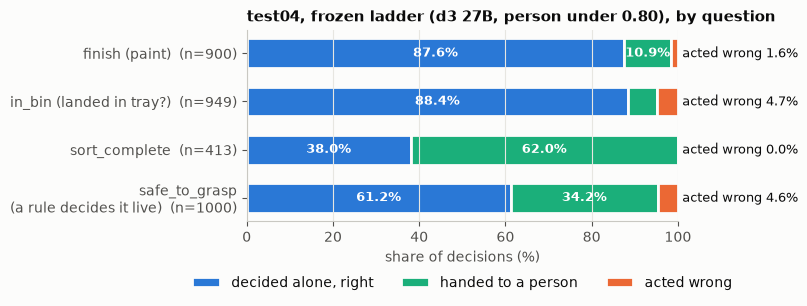

In [5]:
BY_QUESTION_PUBLISHED = {  # confirmation.json by_question: handed to a person, accuracy (acted wrong = 1 - accuracy)
    "finish": (0.1089, 0.9844), "in_bin": (0.0685, 0.9526), "sort_complete": (0.6199, 1.0), "safe_to_grasp": (0.3420, 0.9540),
}
wrong, person, conf = replayed
order = ["finish", "in_bin", "sort_complete", "safe_to_grasp"]
table = {}
print(f"  {'question':14s} {'n':>5s} {'alone, right':>13s} {'to a person':>12s} {'acted wrong':>12s} {'conf. wrong':>12s}   matches")
for q in order:
    m = question == q
    t = {"n": int(m.sum()), "alone_right": (~wrong & ~person)[m].mean(), "person": person[m].mean(),
         "wrong": wrong[m].mean(), "conf_wrong": (wrong & (conf >= CONFIDENT))[m].mean()}
    table[q] = t
    ok = same(t["person"], BY_QUESTION_PUBLISHED[q][0]) and same(1 - t["wrong"], BY_QUESTION_PUBLISHED[q][1])
    mismatches += [] if ok else [("by question", q)]
    print(f"  {q:14s} {t['n']:5d} {t['alone_right']:13.3f} {t['person']:12.3f} {t['wrong']:12.3f} {t['conf_wrong']:12.3f}   {'yes' if ok else 'NO'}")
assert not mismatches, mismatches

fig, ax = plt.subplots(figsize=(8.2, 3.3))
labels = {"finish": "finish (paint)", "in_bin": "in_bin (landed in tray?)", "sort_complete": "sort_complete",
          "safe_to_grasp": "safe_to_grasp\n(a rule decides it live)"}
for i, q in enumerate(order):
    left = 0.0
    for key, colour, name in (("alone_right", BLUE, "decided alone, right"), ("person", AQUA, "handed to a person"),
                              ("wrong", ORANGE, "acted wrong")):
        width = table[q][key] * 100
        ax.barh(i, width, left=left, color=colour, height=0.62, edgecolor="#fcfcfb", linewidth=2, label=name if i == 0 else None)
        if width >= 9:
            ax.text(left + width / 2, i, f"{width:.1f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        elif key == "wrong":
            ax.text(101, i, f"acted wrong {width:.1f}%", ha="left", va="center", color=INK, fontsize=9)
        left += width
ax.set_yticks(range(len(order)), [f"{labels[q]}  (n={table[q]['n']})" for q in order])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("share of decisions (%)")
ax.grid(axis="y", visible=False)
ax.set_title("test04, frozen ladder (d3 27B, person under 0.80), by question")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
fig.tight_layout()

`sort_complete` is mostly handed to the person, and it is never wrong when d3 does answer; most of its hand-offs (198 of 256) come from the crowded episodes, which cannot be finished by design. `in_bin` hands off rarely but carries most of the judgement errors. The next section shows why.

## How the threshold trades the two costs (illustration, not a refit)

The threshold was fitted on test03 and frozen at 0.80. Moving it on test04 after the fact shows the trade-off the fit made; it is not used to choose anything, and test04 is spent for new claims.

at 0.80: acted wrong 2.6%, handed to a person 18.5%
at 0.60: acted wrong 5.1%, handed to a person 7.8%
at 0.90: acted wrong 1.9%, handed to a person 24.8%
at 0.95: acted wrong 1.4%, handed to a person 30.9%


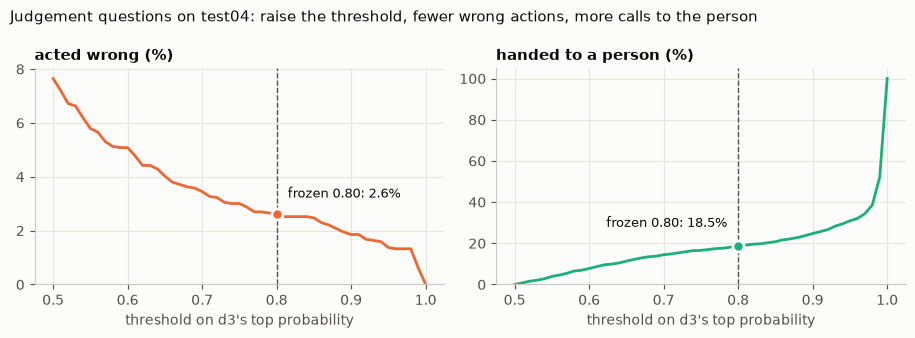

In [6]:
grid = np.round(np.arange(0.50, 1.0001, 0.01), 2)
sweep = []
for t in grid:
    w, p, _ = ladder(threshold=t)
    sweep.append((w[judgement].mean() * 100, p[judgement].mean() * 100))
sweep = np.array(sweep)
at = int(np.flatnonzero(grid == THRESHOLD)[0])

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4), sharex=True, num="plot_threshold_tradeoff")
for ax, col, colour, title in ((axes[0], 0, ORANGE, "acted wrong (%)"), (axes[1], 1, AQUA, "handed to a person (%)")):
    ax.plot(grid, sweep[:, col], color=colour, linewidth=2)
    ax.axvline(THRESHOLD, color=MUTED, linestyle="--", linewidth=1)
    ax.plot([THRESHOLD], [sweep[at, col]], "o", color=colour, markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
    ax.annotate(f"frozen 0.80: {sweep[at, col]:.1f}%", (THRESHOLD, sweep[at, col]), xytext=(8, 12) if col == 0 else (-8, 14),
                textcoords="offset points", ha="left" if col == 0 else "right", color=INK, fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("threshold on d3's top probability")
    ax.set_ylim(bottom=0)
fig.suptitle("Judgement questions on test04: raise the threshold, fewer wrong actions, more calls to the person",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
print(f"at 0.80: acted wrong {sweep[at, 0]:.1f}%, handed to a person {sweep[at, 1]:.1f}%")
for t in (0.6, 0.9, 0.95):
    i = int(np.flatnonzero(grid == t)[0])
    print(f"at {t:.2f}: acted wrong {sweep[i, 0]:.1f}%, handed to a person {sweep[i, 1]:.1f}%")

Raising the threshold buys fewer wrong actions with a lot more of the person's time: at 0.95 acted wrong falls to 1.4%, but 30.9% of calls go to the person instead of 18.5%. And most of what is left at the top is one failure that no sensible threshold fixes.

## The honest weakness: one frame hides a wrong-tray landing from d3

Every `in_bin` error on test04 is d3 saying "yes, it's in the bin" when the truth is "no". Splitting those "no" decisions by where the part actually was (the simulator's geometry check, logged with each decision):

  the part was...   d3 said yes  handed off  said no   yes at 0.9+
  wrong bin                  29           0        0   29
  no bin                     16          65       70   7

wrong-tray decisions: 29, from 15 landings (one per episode; after a "no" the robot looks again, so most landings were asked twice); d3's confidence on them: min 0.945, median 0.990
confidently wrong judgement decisions: 42, of them wrong-tray in_bin calls: 29


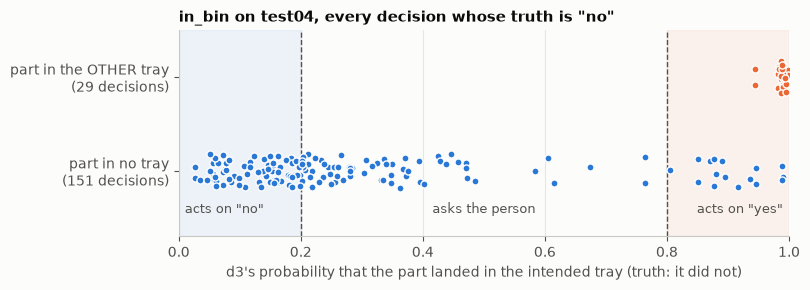

In [7]:
m = (question == "in_bin") & (truth == "no")
did = np.where(person[m], "handed off", np.where(d3_answer[m] == "yes", "said yes", "said no"))
print(f"  {'the part was...':16s} {'d3 said yes':>12s} {'handed off':>11s} {'said no':>8s}   yes at 0.9+")
for where in ("wrong bin", "no bin"):
    k = part_was[m] == where
    said_yes = (did[k] == "said yes")
    print(f"  {where:16s} {said_yes.sum():12d} {(did[k] == 'handed off').sum():11d} {(did[k] == 'said no').sum():8d}"
          f"   {(said_yes & (conf[m][k] >= 0.9)).sum()}")
wb = m & (part_was == "wrong bin")
print(f"\nwrong-tray decisions: {int(wb.sum())}, from {len(set(episode[wb]))} landings (one per episode; after a \"no\" "
      f"the robot looks again, so most landings were asked twice); d3's confidence on them: min {d3_conf[wb].min():.3f}, "
      f"median {np.median(d3_conf[wb]):.3f}")
cw_j = wrong & (conf >= CONFIDENT) & judgement
print(f"confidently wrong judgement decisions: {int(cw_j.sum())}, of them wrong-tray in_bin calls: {int((cw_j & wb).sum())}")
assert [int(((did == s) & (part_was[m] == 'wrong bin')).sum()) for s in ('said yes', 'handed off', 'said no')] == [29, 0, 0]
assert [int(((did == s) & (part_was[m] == 'no bin')).sum()) for s in ('said yes', 'handed off', 'said no')] == [16, 65, 70]

fig, ax = plt.subplots(figsize=(8.2, 3.0), num="plot_wrong_bin_blind_spot")
rng = np.random.default_rng(1)
for i, (where, colour, name) in enumerate((("wrong bin", ORANGE, "in the OTHER tray"), ("no bin", BLUE, "in no tray (table, floor, hand)"))):
    k = m & (part_was == where)
    p_yes = np.array([float(r) for r in d3_conf[k]])
    p_yes = np.where(d3_answer[k] == "yes", p_yes, 1 - p_yes)  # d3's probability for "yes" (two options)
    ax.scatter(p_yes, i + rng.uniform(-0.18, 0.18, k.sum()), s=26, color=colour, edgecolor="#fcfcfb", linewidth=1, zorder=3)
ax.axvspan(THRESHOLD, 1.0, color=ORANGE, alpha=0.07, zorder=0)
ax.axvspan(0, 1 - THRESHOLD, color=BLUE, alpha=0.07, zorder=0)
ax.axvline(THRESHOLD, color=MUTED, linestyle="--", linewidth=1)
ax.axvline(1 - THRESHOLD, color=MUTED, linestyle="--", linewidth=1)
ax.text(0.99, 1.45, "acts on \"yes\"", ha="right", color=MUTED, fontsize=9)
ax.text(0.5, 1.45, "asks the person", ha="center", color=MUTED, fontsize=9)
ax.text(0.01, 1.45, "acts on \"no\"", ha="left", color=MUTED, fontsize=9)
ax.set_yticks([0, 1], ["part in the OTHER tray\n(29 decisions)", "part in no tray\n(151 decisions)"])
ax.set_ylim(-0.5, 1.7)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("d3's probability that the part landed in the intended tray (truth: it did not)")
ax.set_title("in_bin on test04, every decision whose truth is \"no\"")
fig.tight_layout()

**d3 called every wrong-tray landing "in the bin": all 29 of those decisions (15 landings), every one at 0.94 confidence or more.** That is 29 of the 42 confidently wrong judgement calls. Each time the target tray already held an earlier part, so one frame does show a part in that tray, just not this one (example in the log: a scratched part meant for rework, sitting in the good tray, d3 "yes" at 0.99). A small exploratory retest on an earlier log, with a before and an after frame, caught all 8 such checks (4 landings), which is not a scored result. A defective part in the good tray is the costliest error this cell can make, and **no sensible confidence threshold catches it**: the points sit at 0.945 to 0.998, where a cut would also hand the person over half of all judgement calls (52% at 0.99). Parts in no tray are mostly caught (135 of 151 handed off or answered "no").

### The deterministic check for it: load cells under the trays

This is a sensor problem, not a threshold problem. The robot cell has a **load cell under each tray**: the check answers `in_bin` "yes" only when the intended tray got heavier by about one part's weight and the other tray did not (in simulation, the reading is the physics engine's contact force on each tray). In a forced wrong-tray run (2 episodes) the scales caught both landings, the operator moved the part, and both sorts finished 3 of 3; in the recorded Oct 23 demo the load cells said "no" on the wrong-tray part, the operator re-binned it, and they then said "yes".

What that does **not** show: the scales are not part of the frozen ladder, and test04 was logged without them, so this notebook cannot score them. Two episodes and one demo are a smoke check, not a measurement; a new log (test05) would be needed for a number.

## By fault type

In [8]:
FAULT_PUBLISHED = {"clean": 0.0915, "drop_on_carry": 0.1250, "crowded": 0.3527}  # handoff-breakdown.json, judgement handed to a person
print(f"  {'fault type':14s} {'episodes':>8s} {'judgement to a person':>22s} {'per 3-part episode':>19s}   matches")
for f in ("clean", "drop_on_carry", "crowded"):
    k = (fault == f) & judgement
    n_ep = len(set(episode[fault == f]))
    share = person[k].mean()
    ok = same(share, FAULT_PUBLISHED[f])
    mismatches += [] if ok else [("fault", f)]
    print(f"  {f:14s} {n_ep:8d} {share:22.4f} {person[k].sum() / n_ep:19.2f}   {'yes' if ok else 'NO'}")
assert not mismatches, mismatches
print("\nEvery checked number in this notebook equals the project's published output files.")

  fault type     episodes  judgement to a person  per 3-part episode   matches
  clean               100                 0.0915                0.67   yes
  drop_on_carry       100                 0.1250                1.03   yes
  crowded             100                 0.3527                2.49   yes

Every checked number in this notebook equals the project's published output files.


Crowded episodes hand off `sort_complete` almost every time, which is the right call for a sort that cannot be finished.

## What this does not show

- **Simulation only.** Real cameras, real parts and real lighting are not tested.
- **Not live behaviour.** Every decision sits on the path the oracle drove while the log was made; a live robot that acts on d3's answers can reach states this log never visits.
- **Other ladders on test04.** Only the frozen arm was replayed, by design.
- **Why `in_bin` errors rose** from test03 (3.2%) to test04 (4.7%), and why judgement acted-wrong rose from the predicted 1.8% to 2.6%: not established.
- **The load cells' error rate.** See above: a smoke check, not a measurement.

## Data

`data/test04_decisions.csv` has one row per labelled test04 decision: `episode`, `fault`, `question`, `truth`, d3's top answer and probability (`d3_answer`, `d3_confidence`), whether a hard rule answered it while the log was made (`rule_decided`, `rule_answer`), and for `in_bin` where the part was (`part_was`). `data/frozen_ladder.json` holds the frozen ladder, threshold and test03 prediction. Both are written from the full logs by `scripts/export_notebook_data.py` in the project repo.

## Phase 2: a soft-gel capsule cell, VDM against VLM on one base model

The same design on a second job: the robot parks at a tray of soft-gel capsules and picks out the leakers, which differ from good capsules only by the pool under them. Five questions go to a model; the leaker calls are *does this half-tray hold a leaker?* and *is this capsule a leaker?*

**d3 27B (a VDM) is built on Qwen3.8-27B (a VLM)**, so the two read the same pictures with the same base model and differ only in how they answer. Intern-Decision-4B is a second VDM. Qwen is read two ways: the probability of its first answer word, and the confidence it states.

The ladder was picked on a selection log (sel03) by the Phase 1 rule, frozen in `docs/PREREG_CAPSULES.md`, and scored once on **test05**: 150 new shifts, 3,785 decisions. The extract below is every labelled test05 decision with each arm's top answer (`scripts/export_capsule_notebook_data.py`).

In [9]:
# Phase 2: the capsule cell. One row per test05 decision: each replayed arm's top answer and its probability.
with find("test05_decisions.csv").open(encoding="utf-8") as f:
    caps = list(csv.DictReader(f))
frozen_caps = json.loads(find("frozen_ladder_capsules.json").read_text(encoding="utf-8"))
c_question = np.array([r["question"] for r in caps])
c_truth = np.array([r["truth"] for r in caps])
c_shift = np.array([r["shift"] for r in caps])
ANSWER = {arm: np.array([r[f"{arm}_answer"] for r in caps]) for arm in ("intern-4b-vision", "d3-27b-vision", "qwen-27b-vision", "qwen-27b-self-vision")}
CONF = {arm: np.array([float(r[f"{arm}_p"]) for r in caps]) for arm in ANSWER}
RUNGS, C_THRESH = frozen_caps["rungs"], frozen_caps["thresholds"]


def capsule_ladder():
    # Each rung acts when its top answer is at or above its threshold for that question; else the next rung; then a person.
    who = np.full(len(caps), "human", dtype=object)
    answer = c_truth.copy().astype(object)  # the person is taken to be right, as in the scoring
    for rung in RUNGS:
        thr = np.array([C_THRESH[rung][q] for q in c_question])
        take = (who == "human") & (CONF[rung] >= thr)
        who[take] = rung
        answer[take] = ANSWER[rung][take]
    return who, answer


who, c_answer = capsule_ladder()
c_wrong = (who != "human") & (c_answer != c_truth)
c_person = who == "human"
c_conf = np.where(c_person, 1.0, np.select([who == r for r in RUNGS], [CONF[r] for r in RUNGS], 1.0))
n = len(caps)
got = {"acted_wrong": c_wrong.mean(), "confidently_wrong": (c_wrong & (c_conf >= CONFIDENT)).mean(),
       "handed_to_person": c_person.mean(), "alone_right": (~c_wrong & ~c_person).mean()}
CAPS_PUBLISHED = {"acted_wrong": 0.0016, "confidently_wrong": 0.0005, "handed_to_person": 0.0275, "alone_right": 0.9709}  # test05/confirmation.json
CAPS_BY_RUNG = {"intern-4b-vision": 3398, "d3-27b-vision": 283, "human": 104}
print(f"{n:,} decisions in {len(set(c_shift))} shifts; frozen ladder: {' > '.join(RUNGS)} > person (picked on sel03, frozen before test05)")
for k, v in got.items():
    print(f"  {k:18s} {v:.4f}   published {CAPS_PUBLISHED[k]:.4f}   predicted {frozen_caps['prediction'][{'handed_to_person': 'human_rate'}.get(k, k)]:.4f}")
by_rung = {r: int((who == r).sum()) for r in [*RUNGS, "human"]}
print(f"  answered by: {by_rung}")
assert all(round(float(v), 4) == CAPS_PUBLISHED[k] for k, v in got.items()), "the recomputed ladder differs from the published confirmation"
assert by_rung == CAPS_BY_RUNG
print("matches the published test05 confirmation")


3,785 decisions in 150 shifts; frozen ladder: intern-4b-vision > d3-27b-vision > person (picked on sel03, frozen before test05)
  acted_wrong        0.0016   published 0.0016   predicted 0.0053
  confidently_wrong  0.0005   published 0.0005   predicted 0.0005
  handed_to_person   0.0275   published 0.0275   predicted 0.0293
  alone_right        0.9709   published 0.9709   predicted 0.9654
  answered by: {'intern-4b-vision': 3398, 'd3-27b-vision': 283, 'human': 104}
matches the published test05 confirmation


**Reading it.** The frozen ladder acted wrong on 6 of 3,785 decisions (0.16%, predicted 0.53%), handed 2.75% to a person, and decided alone and right on 97.1%. Intern answered most questions; d3 took the ones Intern was unsure of.

467 leaker pictures, 2745 clean
  intern-4b-vision       caught 397   called good at 0.9+:   1   clean called leakers:   2
  d3-27b-vision          caught 397   called good at 0.9+:   1   clean called leakers: 994
  qwen-27b-vision        caught 197   called good at 0.9+:  98   clean called leakers:   0
  qwen-27b-self-vision   caught 296   called good at 0.9+: 171   clean called leakers:   1
matches VALIDATION.md


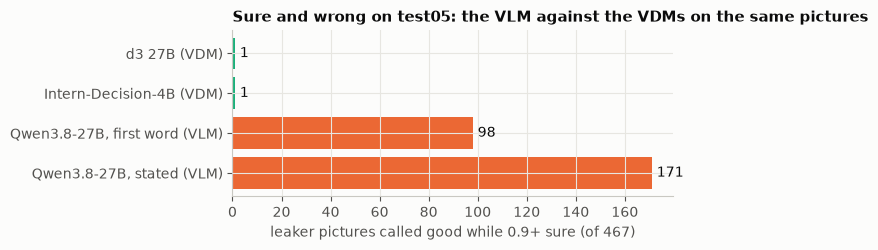

In [10]:
# Every arm alone on the leaker questions: leakers caught, leakers called good at 0.9 or more, clean pictures called leakers.
leak_q = np.isin(c_question, ["leak_block", "leak_capsule"])
is_leaker = np.isin(c_truth, ["yes", "leaker"])
ARM_PUBLISHED = {  # VALIDATION.md "test05": caught, called good at 0.9+ (count), false alarms (of 2,745 clean)
    "d3-27b-vision": (397, 1, 994), "intern-4b-vision": (397, 1, 2),
    "qwen-27b-vision": (197, 98, 0), "qwen-27b-self-vision": (296, 171, 1)}
table = {}
for arm in ANSWER:
    wrong = ANSWER[arm] != c_truth
    lk, cl = leak_q & is_leaker, leak_q & ~is_leaker
    table[arm] = (int((lk & ~wrong).sum()), int((lk & wrong & (CONF[arm] >= CONFIDENT)).sum()), int((cl & wrong).sum()))
print(f"{int((leak_q & is_leaker).sum())} leaker pictures, {int((leak_q & ~is_leaker).sum())} clean")
for arm, (caught, sure_missed, fa) in table.items():
    print(f"  {arm:22s} caught {caught:3d}   called good at 0.9+: {sure_missed:3d}   clean called leakers: {fa:3d}")
assert table == ARM_PUBLISHED, "differs from VALIDATION.md test05"
print("matches VALIDATION.md")

fig, ax = plt.subplots(figsize=(7, 2.6), num="plot_capsule_sure_and_wrong")
names = ["d3 27B (VDM)", "Intern-Decision-4B (VDM)", "Qwen3.8-27B, first word (VLM)", "Qwen3.8-27B, stated (VLM)"]
vals = [table[a][1] for a in ("d3-27b-vision", "intern-4b-vision", "qwen-27b-vision", "qwen-27b-self-vision")]
ax.barh(names[::-1], vals[::-1], color=[ORANGE, ORANGE, AQUA, AQUA])
for i, v in enumerate(vals[::-1]):
    ax.text(v + 2, i, str(v), va="center", color=INK)
ax.set_xlabel("leaker pictures called good while 0.9+ sure (of 467)")
ax.set_title("Sure and wrong on test05: the VLM against the VDMs on the same pictures")
plt.tight_layout()
plt.show()


**Reading it.** On the same 467 leaker pictures, the VLM was 0.9+ sure that **98 to 171** leaking capsules were good, depending on how it was read; each VDM was, once. A model that is sure and wrong passes any confidence threshold, which is why the hand-off only works on a model whose confidence means something. d3 alone over-calls leakers on clean pictures (994 of 2,745), but never at 0.9+, so its thresholds pass those on (why it over-calls is not traced). Simulated cells, not a real line: a pool is the only sign of a leaker here.